# Phase 3b — Baseline checks before building the weighted-KD method
**Mixing-Aware Distillation for Hinglish**

**A. Is the student actually the best efficient model?** Compare an int8-QUANTIZED TEACHER (no distillation at all)
   with the students (fp32 and int8) on test macro-F1, size and CPU latency.
**B. Does vocabulary trimming cost accuracy?** Phase 3 mapped 4.6% of test wordpieces to [UNK]. Retrain the
   `ce_only` student with three vocab sizes (trim2 = Phase 3 setting, trim1, full) x 3 seeds.

Needs: Phase 2 outputs (teacher), Phase 3 outputs (`student_*_best`, `kept_ids.npy`) for Part A.
Time (estimate, unmeasured): Part A ~10 min, Part B ~15 min on a T4.
Copy everything under `════ REPORT BACK ════` markers and send it back.

In [2]:
# CELL 1: Imports, config, locate Phase 2/3 outputs
import os, sys, re, json, time, copy, random, shutil, subprocess, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ── Config ───────────────────────────────────────────────────────────────────
SEEDS        = [13, 42, 2024]
RUN_ARMS     = ["ce_only", "kd_plain"]          # optional ablations: add "kd_logits", "kd_labeled"
EPOCHS       = 3
LR           = 5e-5
BATCH        = 32
MAXLEN       = 160
WARMUP_FRAC  = 0.10
WEIGHT_DECAY = 0.01
TEMP         = 2.0                              # KD temperature
LAYER_MAP    = [1, 3, 5, 7, 9, 11]              # teacher layers (0-indexed) copied into the 6 student layers.
                                                # Odd layers so the LAST student layer matches the teacher's final layer.
                                                # (Phase 1 planned [0,2,4,6,8,10]; set that here to revert.)
TRIM_VOCAB       = True
VOCAB_MIN_COUNT  = 2                            # keep wordpieces seen >=2x in train+dev+transfer (test is NOT used)
MIN_LANG_TOKENS  = 4                            # transfer-set filter
N_TRANSFER_MAX   = None                         # e.g. 20000 to speed up; None = use all
N_BOOT       = 1000
MIN_BIN_N    = 50
USE_DRIVE    = True
VOCAB_VARIANTS    = {"trim2": 2, "trim1": 1, "full": None}   # min wordpiece count to keep; None = full 30,522 vocab
RUN_KD_FULLVOCAB = False        # also train kd_plain with the full vocab (seed 1 only, ~11 min) as an extra check
LAT_THREADS  = 4                # CPU threads for latency (Colab usually has 2)

ARMS = {   # alpha = weight on gold-label CE; (1-alpha) on logit KL; beta = weight on hidden-state MSE
    "ce_only":    dict(alpha=1.0, beta=0.0, use_kl=False, unlabeled=False, teacher=False),
    "kd_labeled": dict(alpha=0.5, beta=1.0, use_kl=True,  unlabeled=False, teacher=True),
    "kd_logits":  dict(alpha=0.5, beta=0.0, use_kl=True,  unlabeled=True,  teacher=True),
    "kd_plain":   dict(alpha=0.5, beta=1.0, use_kl=True,  unlabeled=True,  teacher=True),
}
LABELS = ["negative", "neutral", "positive"]; LABEL2ID = {l: i for i, l in enumerate(LABELS)}; K = 3

DRIVE_ROOT = Path("/content/drive/MyDrive/mixing_aware_kd")
drive_ok = False
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive"); drive_ok = True
    except Exception as e:
        print(f"(Drive not mounted: {type(e).__name__})")

from safetensors import safe_open
try:
    import torch as _t; _FW = "pt"
except Exception:
    _FW = "np"

def ckpt_ok(d):
    """True only if the checkpoint can actually be read end to end (catches half-written Drive copies)."""
    d = Path(d); f = d / "model.safetensors"
    if not f.exists(): return (d / "pytorch_model.bin").exists()
    try:
        with safe_open(str(f), framework=_FW) as sf:
            ks = list(sf.keys()); sf.get_tensor(ks[0]); sf.get_tensor(ks[-1])
        return True
    except Exception as e:
        print(f"  unreadable checkpoint {f} ({f.stat().st_size/1e6:.0f} MB): {type(e).__name__}: {str(e)[:70]}"); return False

def find_phase2():
    for c in [Path("/content/phase2_outputs"), Path("./phase2_outputs"), DRIVE_ROOT / "phase2"]:   # local copy first
        if not (c / "split_train_uids.csv").exists(): continue
        for name in ("teacher_best", "teacher_best_model"):
            if (c / name).exists() and ckpt_ok(c / name): return c, c / name
    return None, None

P2, TEACHER_DIR = find_phase2()
if P2 is None:
    raise FileNotFoundError(
        "No READABLE teacher checkpoint found. If only a truncated Drive copy exists: re-run the Phase 2 notebook after deleting "
        "the best seed's seedXXXX_result.json and the teacher_best folder (other seeds are cached, so only that seed retrains, ~5-10 min).")
if drive_ok and not str(P2).startswith(str(DRIVE_ROOT)):          # back up to Drive, then VERIFY the copy
    dst = DRIVE_ROOT / "phase2"; dst.mkdir(parents=True, exist_ok=True)
    print(f"Free space on Drive: {shutil.disk_usage('/content/drive').free/1e9:.1f} GB")
    shutil.copytree(P2, dst, dirs_exist_ok=True)
    try:
        drive.flush_and_unmount(); drive.mount("/content/drive")      # forces Drive to finish writing
    except Exception as e:
        print("(flush skipped:", type(e).__name__, ")")
    print("Drive backup verified." if ckpt_ok(dst / TEACHER_DIR.name) else
          "WARNING: Drive backup of the teacher is incomplete (Drive full or sync interrupted). Using the local copy; free up Drive space and re-copy.")
p2_summary = json.loads((P2 / "phase2_summary.json").read_text())
BEST_T_SEED = p2_summary["best_seed_for_phase3"]
OUT_DIR = (DRIVE_ROOT / "phase3b") if drive_ok else Path("./phase3b_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True); (OUT_DIR / "figures").mkdir(exist_ok=True)
DATA_DIR = Path("./data"); DATA_DIR.mkdir(exist_ok=True)
print(f"Phase 2 dir: {P2}\nTeacher: {TEACHER_DIR} (seed {BEST_T_SEED})\nPhase 3 outputs: {OUT_DIR}")


def find_phase3():
    for c in [Path("/content/phase3_outputs"), Path("./phase3_outputs"), DRIVE_ROOT / "phase3"]:
        if (c / "kept_ids.npy").exists() and (c / "student_ce_only_best").exists(): return c
    return None
P3 = find_phase3()
if P3 is None:
    print("Phase 3 outputs not found -> Baseline A will only cover the teacher (no student checkpoints).")
elif drive_ok and not str(P3).startswith(str(DRIVE_ROOT)):
    dst3 = DRIVE_ROOT / "phase3"; shutil.copytree(P3, dst3, dirs_exist_ok=True)
    print("Phase 3 backup to Drive:", "verified" if all(ckpt_ok(dst3 / f"student_{a}_best") for a in ["ce_only", "kd_plain"] if (dst3 / f"student_{a}_best").exists()) else "INCOMPLETE")
if not drive_ok:
    print("WARNING: Drive is not mounted. /content/phase2_outputs and /content/phase3_outputs are lost if the runtime resets. "
          "Run `from google.colab import drive; drive.mount('/content/drive')` in a cell and re-run this cell, or download the folders.")

try:
    import torch, torch.nn.functional as F
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
except Exception:
    torch = None; F = None; DEVICE = "cpu"
print("Device:", DEVICE)
if str(DEVICE) == "cpu": print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU.")

(Drive not mounted: MessageError)
Phase 2 dir: /content/phase2_outputs
Teacher: /content/phase2_outputs/teacher_best (seed 2024)
Phase 3 outputs: phase3b_outputs
Device: cuda


In [3]:
# CELL 2: Rebuild Phase 2 splits + gold CMI metrics
URL_RE = re.compile(r"^(https?://|www\.)\S+$", re.I); MENTION_RE = re.compile(r"^@\w+$")
HASHTAG_RE = re.compile(r"^#\w+"); NONWORD_RE = re.compile(r"^[\d\W_]+$")

def parse_semeval_conll(path):
    sents, cur = [], None
    with open(path, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\r\n")
            if line.startswith("meta\t"):
                if cur is not None: sents.append(cur)
                p = line.split("\t")
                cur = {"uid": p[1].strip(), "label": (p[2].strip() if len(p) > 2 and p[2].strip() else None),
                       "tokens": [], "raw_tags": []}
            elif not line.strip(): continue
            elif cur is not None:
                p = line.split("\t"); cur["tokens"].append(p[0]); cur["raw_tags"].append(p[1].strip() if len(p) > 1 else "")
    if cur is not None: sents.append(cur)
    return sents

def norm_gold_tag(t):
    t = re.sub(r"[^A-Za-z]", "", t).lower()
    return "HI" if t.startswith("hin") else "EN" if t.startswith("eng") else "OTHER"

def independent_mask(tokens):
    m = [False] * len(tokens)
    for i, t in enumerate(tokens):
        prev = tokens[i - 1] if i > 0 else ""
        if URL_RE.match(t) or MENTION_RE.match(t) or HASHTAG_RE.match(t) or NONWORD_RE.match(t) or prev in ("@", "#"):
            m[i] = True
    return m

def finalize_tags(tokens, base_tags):
    m = independent_mask(tokens); return ["OTHER" if m[i] else base_tags[i] for i in range(len(tokens))]

def build_text(tokens):
    out, i = [], 0
    while i < len(tokens):
        t = tokens[i]
        if t == "@" and i + 1 < len(tokens): out.append("@user"); i += 2; continue
        out.append("http" if URL_RE.match(t) else t); i += 1
    return " ".join(out)

def compute_cmi(tags):
    lang = [t for t in tags if t in ("HI", "EN")]; n, u = len(tags), len(tags) - len(lang)
    if (n - u) <= 1: return 0.0
    return (len(lang) - max(Counter(lang).values())) / (n - u)

def compute_sd(tags):
    lang = [t for t in tags if t in ("HI", "EN")]
    if len(lang) <= 1: return 0.0
    return sum(lang[i] != lang[i + 1] for i in range(len(lang) - 1)) / (len(lang) - 1)

def abs_cmi_bin(c):
    return "mono" if c == 0 else "low" if c < 0.20 else "mid" if c < 0.35 else "high"
ABS_ORDER = ["mono", "low", "mid", "high"]

def quantile_bins(x, q=5):
    x = np.asarray(x, float); edges = np.unique(np.quantile(x, np.linspace(0, 1, q + 1)))
    if len(edges) < 3: return np.zeros(len(x), int), ["all"]
    idx = np.clip(np.digitize(x, edges[1:-1], right=False), 0, len(edges) - 2)
    labels = [f"Q{i+1} [{edges[i]:.2f},{edges[i+1]:.2f}{']' if i == len(edges)-2 else ')'}" for i in range(len(edges) - 1)]
    return idx, labels

def macro_f1_np(y, p, k=K):
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros(k), where=den > 0); present = cm.sum(1) > 0
    return float(f1[present].mean()) if present.any() else float("nan")

def to_df(sents):
    df = pd.DataFrame(sents)
    df["gold_tags"] = [finalize_tags(t, [norm_gold_tag(x) for x in rt]) for t, rt in zip(df["tokens"], df["raw_tags"])]
    df["text"] = df["tokens"].apply(build_text); df["raw_text"] = df["tokens"].apply(lambda t: " ".join(t))
    return df

def add_gold_metrics(df):
    df["cmi_gold"] = [compute_cmi(t) for t in df.gold_tags]; df["sd_gold"] = [compute_sd(t) for t in df.gold_tags]
    df["nlang_gold"] = [sum(x in ("HI", "EN") for x in t) for t in df.gold_tags]; return df

SEMEVAL_DIR = DATA_DIR / "semeval"
if not SEMEVAL_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/singhnivedita/SemEval2020-Task9.git", str(SEMEVAL_DIR)], capture_output=True)
ORIG = SEMEVAL_DIR / "Pre Processing Code" / "Original Dataset"; TY = SEMEVAL_DIR / "Fully Processed Datasets" / "Ty.txt"
raw_train, raw_val, raw_test = [to_df(parse_semeval_conll(ORIG / f)) for f in ["Train.txt", "Validation.txt", "Test.txt"]]
ty = pd.read_csv(TY, dtype=str); raw_test["label"] = raw_test["uid"].map(dict(zip(ty["Uid"].str.strip(), ty["Sentiment"].str.strip().str.lower())))
all_df = pd.concat([raw_train, raw_val], ignore_index=True).drop_duplicates("uid")

def from_split(csv):
    s = pd.read_csv(P2 / csv, dtype={"uid": str}); d = s[["uid"]].merge(all_df, on="uid", how="left")
    assert d["tokens"].notna().all(), f"{csv}: some UIDs not found in raw data"
    d["y"] = d["label"].map(LABEL2ID); assert (d["y"].values == s["y"].values).all(), f"{csv}: labels differ from Phase 2"
    return add_gold_metrics(d)

tr_df, dev_df = from_split("split_train_uids.csv"), from_split("split_dev_uids.csv")
te_df = add_gold_metrics(raw_test.reset_index(drop=True)); te_df["y"] = te_df["label"].map(LABEL2ID)
y_te = te_df.y.values.astype(int)

p2pred = pd.read_csv(P2 / "teacher_test_predictions.csv", dtype={"uid": str})
assert (p2pred.uid.values == te_df.uid.values).all(), "Test order differs from Phase 2"
cmi_diff = np.abs(p2pred.iloc[:, p2pred.columns.get_loc("cmi_gold")].values - te_df.cmi_gold.values).max() if "cmi_gold" in p2pred else float("nan")
P_T_ALL = np.load(P2 / "teacher_test_probs_all_seeds.npy")                       # (S,N,K) Phase 2 seeds
P_T = np.load(P2 / f"seed{BEST_T_SEED}_test_probs.npy").argmax(1)                # frozen teacher predictions (N,)
print(f"train={len(tr_df)} dev={len(dev_df)} test={len(te_df)} | max |CMI diff vs Phase 2| = {cmi_diff:.2e}")
print(f"Frozen teacher (seed {BEST_T_SEED}) test macro-F1 from Phase 2 file = {macro_f1_np(y_te, P_T):.4f}")

train=13931 dev=1548 test=3000 | max |CMI diff vs Phase 2| = 9.71e-17
Frozen teacher (seed 2024) test macro-F1 from Phase 2 file = 0.7337


In [4]:
# CELL 3: Transfer set from HingLID
import urllib.request
LID_DIR = DATA_DIR / "L3Cube-HingLID"; LID_DIR.mkdir(exist_ok=True)
BASE = "https://raw.githubusercontent.com/l3cube-pune/code-mixed-nlp/main/L3Cube-HingLID"
def parse_hinglid(fp):
    sents, toks, tags = [], [], []
    with open(fp, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\r\n")
            if not line.strip():
                if toks: sents.append((toks, tags)); toks, tags = [], []
                continue
            p = line.split("\t")
            if len(p) >= 2: toks.append(p[0]); tags.append("HI" if p[-1].strip().upper().startswith("HI") else "EN")
    if toks: sents.append((toks, tags))
    return sents
hl = []
for split in ["train", "validation"]:                         # HingLID test is left untouched for tagger work
    fp = LID_DIR / f"{split}.txt"
    if not fp.exists(): urllib.request.urlretrieve(f"{BASE}/{split}.txt", str(fp))
    hl += parse_hinglid(fp)

test_texts = set(raw_test.raw_text.str.lower())
rows, seen = [], set()
for toks, base in hl:
    key = " ".join(toks).lower()
    if key in seen or key in test_texts: continue
    seen.add(key); tags = finalize_tags(toks, base)
    nl = sum(t in ("HI", "EN") for t in tags)
    if nl < MIN_LANG_TOKENS: continue
    rows.append({"uid": f"hl{len(rows)}", "tokens": toks, "gold_tags": tags, "text": build_text(toks), "y": -1,
                 "cmi_gold": compute_cmi(tags), "sd_gold": compute_sd(tags), "nlang_gold": nl})
transfer = pd.DataFrame(rows)
if N_TRANSFER_MAX and len(transfer) > N_TRANSFER_MAX: transfer = transfer.sample(N_TRANSFER_MAX, random_state=0).reset_index(drop=True)
t_save = transfer.copy(); t_save["tokens"] = t_save.tokens.apply(json.dumps); t_save["gold_tags"] = t_save.gold_tags.apply(json.dumps)
t_save.to_csv(OUT_DIR / "transfer_set.csv.gz", index=False)

print("=" * 70); print("════ REPORT BACK: TRANSFER SET ════"); print("=" * 70)
print(f"HingLID sentences read: {len(hl)} -> kept {len(transfer)} (dedup, no exact test-text matches, >= {MIN_LANG_TOKENS} language tokens)")
cmp = pd.DataFrame({"set": ["SemEval train (labeled)", "HingLID transfer (unlabeled)"],
                    "n": [len(tr_df), len(transfer)],
                    "mean_CMI": [tr_df.cmi_gold.mean(), transfer.cmi_gold.mean()],
                    "mean_SD": [tr_df.sd_gold.mean(), transfer.sd_gold.mean()],
                    "mean_lang_tokens": [tr_df.nlang_gold.mean(), transfer.nlang_gold.mean()]})
print(cmp.round(3).to_string(index=False))
print("CMI bin shares (%):")
for nm, d in [("SemEval", tr_df), ("HingLID", transfer)]:
    print(f"  {nm:8s}", (d.cmi_gold.apply(abs_cmi_bin).value_counts(normalize=True).reindex(ABS_ORDER).fillna(0) * 100).round(1).to_dict())
print("Large gaps above mean the transfer set is a different distribution from the eval data; interpret KD gains accordingly.")

════ REPORT BACK: TRANSFER SET ════
HingLID sentences read: 38035 -> kept 37584 (dedup, no exact test-text matches, >= 4 language tokens)
                         set     n  mean_CMI  mean_SD  mean_lang_tokens
     SemEval train (labeled) 13931     0.277    0.187            19.235
HingLID transfer (unlabeled) 37584     0.262    0.317            30.209
CMI bin shares (%):
  SemEval  {'mono': 0.6, 'low': 26.3, 'mid': 45.1, 'high': 28.0}
  HingLID  {'mono': 0.0, 'low': 32.6, 'mid': 43.3, 'high': 24.1}
Large gaps above mean the transfer set is a different distribution from the eval data; interpret KD gains accordingly.


In [5]:
# CELL 4: Load teacher, tokenize, verify
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

tok = AutoTokenizer.from_pretrained(TEACHER_DIR)
teacher = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).to(DEVICE).eval()
for p_ in teacher.parameters(): p_.requires_grad_(False)
USE_AMP = str(DEVICE) == "cuda"

def encode(texts): return tok(list(texts), truncation=True, max_length=MAXLEN)
enc = {n: encode(d.text) for n, d in [("tr", tr_df), ("dev", dev_df), ("te", te_df), ("tf", transfer)]}

class DS(torch.utils.data.Dataset):
    def __init__(self, enc_, y, w=None):
        self.enc, self.y, self.keys = enc_, list(y), list(enc_.keys()); self.w = np.ones(len(self.y)) if w is None else np.asarray(w, float)
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.keys}; item["labels"] = int(self.y[i]); item["ex_w"] = float(self.w[i]); return item

def collate(batch):
    labels = torch.tensor([b.pop("labels") for b in batch]); w = torch.tensor([b.pop("ex_w") for b in batch], dtype=torch.float)
    out = tok.pad(batch, return_tensors="pt"); out["labels"] = labels; out["ex_w"] = w; return out

def merge_enc(a, b):
    return {k: list(a[k]) + list(b[k]) for k in a.keys()}

@torch.no_grad()
def predict_probs(model, loader, remap=None):
    model.eval(); outs = []
    for b in loader:
        ids = b["input_ids"].to(DEVICE)
        if remap is not None: ids = remap[ids]
        kw = {"input_ids": ids, "attention_mask": b["attention_mask"].to(DEVICE)}
        if "token_type_ids" in b: kw["token_type_ids"] = b["token_type_ids"].to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**kw).logits
        outs.append(torch.softmax(logits.float(), -1).cpu().numpy())
    return np.concatenate(outs)

te_loader = torch.utils.data.DataLoader(DS(enc["te"], te_df.y), batch_size=128, collate_fn=collate)
dev_loader = torch.utils.data.DataLoader(DS(enc["dev"], dev_df.y), batch_size=128, collate_fn=collate)
chk = predict_probs(teacher, te_loader)
agree = float((chk.argmax(1) == P_T).mean())
print("=" * 70); print("════ REPORT BACK: TEACHER REPRODUCTION CHECK ════"); print("=" * 70)
print(f"Reloaded teacher test macro-F1 = {macro_f1_np(y_te, chk.argmax(1)):.4f}  vs Phase 2 file {macro_f1_np(y_te, P_T):.4f}; "
      f"prediction agreement = {agree:.2%} (expect ~99-100%; small diffs are fp16 rounding)")
assert agree > 0.97, "Loaded teacher does not match Phase 2 predictions: wrong checkpoint or tokenizer?"

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

════ REPORT BACK: TEACHER REPRODUCTION CHECK ════
Reloaded teacher test macro-F1 = 0.7337  vs Phase 2 file 0.7337; prediction agreement = 100.00% (expect ~99-100%; small diffs are fp16 rounding)


In [8]:
# CELL 5: Baseline A — int8-quantized teacher vs students (accuracy, size, CPU speed)
import io
torch.set_num_threads(min(os.cpu_count() or 1, LAT_THREADS))
cpu_name = subprocess.run("lscpu | grep 'Model name'", shell=True, capture_output=True, text=True).stdout.strip()
print("=" * 70); print("════ REPORT BACK: BASELINE A (quantized teacher vs students) ════"); print("=" * 70)
print(f"{cpu_name} | cpu_count={os.cpu_count()} | torch threads={torch.get_num_threads()} | batch-1 latency, fp32 activations")

def n_params(m): return sum(p.numel() for p in m.parameters())
V = teacher.config.vocab_size; unk_id = tok.unk_token_id

def make_remap_cpu(kept):
    unk_new = int(np.where(kept == unk_id)[0][0]); r = np.full(V, unk_new, dtype=np.int64); r[kept] = np.arange(len(kept))
    return torch.tensor(r)

QUANT_ERR = []
def quantize_int8(model):
    """PyTorch dynamic int8 quantization of Linear layers (embeddings stay fp32). Returns None if this torch build lacks the API."""
    m = copy.deepcopy(model).cpu().eval()
    for modpath in ("torch.ao.quantization", "torch.quantization"):
        try:
            import importlib
            qd = importlib.import_module(modpath).quantize_dynamic
            return qd(m, {torch.nn.Linear}, dtype=torch.qint8)
        except Exception as e:
            QUANT_ERR.append(f"{modpath}: {type(e).__name__}: {str(e)[:80]}")
    return None

def size_mb(model):
    buf = io.BytesIO(); torch.save(model.state_dict(), buf); return buf.tell() / 1e6

KEYS = list(enc["te"].keys()); N_te = len(y_te)
order = np.argsort([len(x) for x in enc["te"]["input_ids"]])

def predict_cpu(model, remap_cpu=None, bs=32):
    probs = np.zeros((N_te, K))
    with torch.inference_mode():
        for i in range(0, N_te, bs):
            idx = order[i:i + bs]
            b = tok.pad([{k: enc["te"][k][j] for k in KEYS} for j in idx], return_tensors="pt")
            ids = remap_cpu[b["input_ids"]] if remap_cpu is not None else b["input_ids"]
            kw = {"input_ids": ids, "attention_mask": b["attention_mask"]}
            if "token_type_ids" in b: kw["token_type_ids"] = b["token_type_ids"]
            probs[idx] = torch.softmax(model(**kw).logits.float(), -1).numpy()
    return probs

lat_texts = te_df.sample(100, random_state=0).text.tolist()
def latency_b1(model, remap_cpu=None):
    times = []
    with torch.inference_mode():
        for i, t in enumerate(lat_texts + lat_texts[:10]):                 # first 10 calls = warm-up
            e = tok(t, truncation=True, max_length=MAXLEN, return_tensors="pt")
            ids = remap_cpu[e["input_ids"]] if remap_cpu is not None else e["input_ids"]
            kw = {"input_ids": ids, "attention_mask": e["attention_mask"]}
            if "token_type_ids" in e: kw["token_type_ids"] = e["token_type_ids"]
            t0 = time.perf_counter(); model(**kw); dt = (time.perf_counter() - t0) * 1000
            if i >= 10: times.append(dt)
    return statistics.median(times), float(np.percentile(times, 90))
import statistics

MODELS, FP32_PARAMS = {}, {}
teacher_cpu = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).eval()
MODELS["teacher_fp32"] = (teacher_cpu, None); FP32_PARAMS["teacher_fp32"] = n_params(teacher_cpu)
_q = quantize_int8(teacher_cpu)
if _q is not None: MODELS["teacher_int8"] = (_q, None); FP32_PARAMS["teacher_int8"] = FP32_PARAMS["teacher_fp32"]
else: print("INT8 QUANTIZATION UNAVAILABLE in this torch build:", QUANT_ERR, "-> int8 rows skipped; send me this message and I will add the ONNX Runtime route.")
if P3 is not None:
    remap3 = make_remap_cpu(np.load(P3 / "kept_ids.npy"))
    for arm in ["ce_only", "kd_plain"]:
        d = P3 / f"student_{arm}_best"
        if d.exists() and ckpt_ok(d):
            s = AutoModelForSequenceClassification.from_pretrained(d).eval()
            MODELS[f"student_{arm}_fp32"] = (s, remap3); FP32_PARAMS[f"student_{arm}_fp32"] = n_params(s)
            _qs = quantize_int8(s)
            if _qs is not None: MODELS[f"student_{arm}_int8"] = (_qs, remap3); FP32_PARAMS[f"student_{arm}_int8"] = n_params(s)

QRES = {}
for name, (m, rm) in MODELS.items():
    t0 = time.perf_counter(); pr = predict_cpu(m, rm); tt = time.perf_counter() - t0
    med, p90 = latency_b1(m, rm); pred = pr.argmax(1)
    QRES[name] = dict(pred=pred, f1=macro_f1_np(y_te, pred), acc=float(np.mean(pred == y_te)), ms_batched=tt / N_te * 1000,
                      lat_med=med, lat_p90=p90, size=size_mb(m), params_M=FP32_PARAMS[name] / 1e6)
    print(f"  {name:22s} F1={QRES[name]['f1']:.4f}  b1 median {med:6.1f} ms  size {QRES[name]['size']:6.1f} MB")

rngA = np.random.default_rng(0); B = N_BOOT
boot = {n: np.empty(B) for n in QRES}
for b in range(B):
    s = rngA.integers(0, N_te, N_te)
    for n in QRES: boot[n][b] = macro_f1_np(y_te[s], QRES[n]["pred"][s])
base = "teacher_fp32"; rows = []
for n, r in QRES.items():
    d = boot[n] - boot[base]
    rows.append({"model": n, "params_M": r["params_M"], "size_MB": r["size"], "b1_median_ms": r["lat_med"], "b1_p90_ms": r["lat_p90"],
                 "batched_ms/ex": r["ms_batched"], "speedup_vs_teacher": QRES[base]["lat_med"] / r["lat_med"], "macro_F1": r["f1"],
                 "ΔF1_vs_teacher_fp32": f"{r['f1'] - QRES[base]['f1']:+.4f} [{np.percentile(d,2.5):+.4f},{np.percentile(d,97.5):+.4f}]"})
tableA = pd.DataFrame(rows); print("\n" + tableA.round(3).to_string(index=False))
print("\nNotes: students are the single best-DEV checkpoint per arm from Phase 3 (selected on dev, not test), so their F1 differs from the 3-seed means.")
print("int8 here = PyTorch dynamic quantization of Linear layers; embeddings stay fp32, so size shrinks less than 4x. ONNX Runtime int8 is a Phase 5 item.")
nd = [n for n, r in QRES.items() if not any((o["lat_med"] <= r["lat_med"] and o["f1"] >= r["f1"] and (o["lat_med"] < r["lat_med"] or o["f1"] > r["f1"])) for m_, o in QRES.items() if m_ != n)]
print("Not dominated on (latency, F1) point estimates:", nd, " (differences inside the CIs above are not real wins)")

════ REPORT BACK: BASELINE A (quantized teacher vs students) ════
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz | cpu_count=2 | torch threads=2 | batch-1 latency, fp32 activations


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

  teacher_fp32           F1=0.7337  b1 median  129.5 ms  size  438.0 MB
  teacher_int8           F1=0.7110  b1 median   67.5 ms  size  181.5 MB
  student_ce_only_fp32   F1=0.7210  b1 median   64.8 ms  size  212.4 MB
  student_ce_only_int8   F1=0.7045  b1 median   34.3 ms  size   83.3 MB
  student_kd_plain_fp32  F1=0.7281  b1 median   66.5 ms  size  212.4 MB
  student_kd_plain_int8  F1=0.7186  b1 median   34.6 ms  size   83.3 MB

                model  params_M  size_MB  b1_median_ms  b1_p90_ms  batched_ms/ex  speedup_vs_teacher  macro_F1       ΔF1_vs_teacher_fp32
         teacher_fp32   109.485  438.017       129.507    153.302         68.236               1.000     0.734 +0.0000 [+0.0000,+0.0000]
         teacher_int8   109.485  181.494        67.489     88.317         54.210               1.919     0.711 -0.0228 [-0.0339,-0.0119]
 student_ce_only_fp32    53.093  212.414        64.791     78.049         35.930               1.999     0.721 -0.0127 [-0.0256,+0.0012]
 student_ce_only_in

In [9]:
# CELL 6: Loss helpers (same as Phase 3, used by Part B)
def hidden_loss(s_hs, t_hs, mask, ex_w, layer_map=LAYER_MAP):
    """MSE between student layer j output and teacher layer layer_map[j] output (hidden_states index L+1)."""
    m = mask.float() * ex_w[:, None]; tot = 0.0
    for j, L in enumerate(layer_map, start=1):
        per_tok = ((s_hs[j].float() - t_hs[L + 1].float()) ** 2).mean(-1)
        tot = tot + (per_tok * m).sum() / m.sum().clamp(min=1e-8)
    return tot / len(layer_map)

def kd_terms(s_out, t_out, labels, mask, ex_w, arm):
    sl = s_out.logits.float(); lab = labels >= 0; zero = sl.new_zeros(())
    ce = F.cross_entropy(sl[lab], labels[lab]) if lab.any() else zero
    loss = arm["alpha"] * ce; kl = hid = zero
    if arm["use_kl"]:
        t_logp = F.log_softmax(t_out.logits.float() / TEMP, -1); s_logp = F.log_softmax(sl / TEMP, -1)
        kl_row = (t_logp.exp() * (t_logp - s_logp)).sum(-1) * TEMP * TEMP
        kl = (ex_w * kl_row).sum() / ex_w.sum().clamp(min=1e-8); loss = loss + (1 - arm["alpha"]) * kl
    if arm["beta"] > 0:
        hid = hidden_loss(s_out.hidden_states, t_out.hidden_states, mask, ex_w); loss = loss + arm["beta"] * hid
    return loss, ce.detach(), kl.detach(), hid.detach() if torch.is_tensor(hid) else zero

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def run_arm_seed(arm_name, seed):
    arm = ARMS[arm_name]; tag = f"{arm_name}_seed{seed}"
    rp = OUT_DIR / f"{tag}_result.json"
    if rp.exists():
        r = json.loads(rp.read_text()); r["test_probs"] = np.load(OUT_DIR / f"{tag}_test_probs.npy")
        print(f"{tag}: cached (dev F1={r['dev_f1']:.4f}, test F1={r['test_f1']:.4f})"); return r
    set_seed(seed)
    student = build_student().to(DEVICE)
    if arm["unlabeled"]:
        enc_tr = merge_enc(enc["tr"], enc["tf"]); y_tr = list(tr_df.y) + [-1] * len(transfer)
    else:
        enc_tr = enc["tr"]; y_tr = list(tr_df.y)
    g = torch.Generator(); g.manual_seed(seed)
    tl = torch.utils.data.DataLoader(DS(enc_tr, y_tr), batch_size=BATCH, shuffle=True, collate_fn=collate, generator=g)
    nd = ["bias", "LayerNorm.weight"]
    groups = [{"params": [p for n, p in student.named_parameters() if not any(x in n for x in nd)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in student.named_parameters() if any(x in n for x in nd)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=LR); total = EPOCHS * len(tl)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    y_dev = dev_df.y.values.astype(int); best_f1, best_state, t0 = -1.0, None, time.time()
    print(f"{tag}: {len(tl)} steps/epoch, {len(y_tr)} rows")
    for ep in range(EPOCHS):
        student.train(); acc = np.zeros(4)
        for step, b in enumerate(tl):
            b = {k: v.to(DEVICE) for k, v in b.items()}
            kw_t = {"input_ids": b["input_ids"], "attention_mask": b["attention_mask"]}
            kw_s = {"input_ids": remap_t[b["input_ids"]], "attention_mask": b["attention_mask"]}
            if "token_type_ids" in b: kw_t["token_type_ids"] = kw_s["token_type_ids"] = b["token_type_ids"]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                t_out = None
                if arm["teacher"]:
                    with torch.no_grad(): t_out = teacher(**kw_t, output_hidden_states=arm["beta"] > 0)
                s_out = student(**kw_s, output_hidden_states=arm["beta"] > 0)
                loss, ce, kl, hid = kd_terms(s_out, t_out, b["labels"], b["attention_mask"], b["ex_w"], arm)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(student.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
            acc += np.array([loss.item(), ce.item(), kl.item(), hid.item()])
        acc /= len(tl)
        f1 = macro_f1_np(y_dev, predict_probs(student, dev_loader, remap_t).argmax(1))
        print(f"  {tag} ep{ep+1}/{EPOCHS} loss={acc[0]:.4f} (ce={acc[1]:.3f} kl={acc[2]:.3f} hid={acc[3]:.3f}) dev_macroF1={f1:.4f} ({time.time()-t0:.0f}s)")
        if f1 > best_f1: best_f1 = f1; best_state = {k: v.detach().cpu().clone() for k, v in student.state_dict().items()}
    student.load_state_dict(best_state)
    probs = predict_probs(student, te_loader, remap_t); test_f1 = macro_f1_np(y_te, probs.argmax(1))
    sdir = OUT_DIR / f"student_{arm_name}_best"
    best_file = OUT_DIR / f"student_{arm_name}_best_dev.txt"
    prev = float(best_file.read_text()) if best_file.exists() else -1.0
    if best_f1 > prev:
        student.save_pretrained(sdir); best_file.write_text(str(best_f1))
    np.save(OUT_DIR / f"{tag}_test_probs.npy", probs)
    res = {"arm": arm_name, "seed": seed, "dev_f1": float(best_f1), "test_f1": float(test_f1), "params": n_params(student)}
    rp.write_text(json.dumps(res)); del student, opt, best_state
    if USE_AMP: torch.cuda.empty_cache()
    res["test_probs"] = probs
    print(f"{tag}: best dev F1={best_f1:.4f} -> test macro-F1={test_f1:.4f} ({time.time()-t0:.0f}s)"); return res

In [10]:
# CELL 7: Baseline B — vocabulary trimming ablation (ce_only student, 3 vocab sizes x seeds)
special = sorted(set(tok.all_special_ids))
all_ids = np.concatenate([np.array(x, dtype=np.int64) for n in ["tr", "dev", "tf"] for x in enc[n]["input_ids"]])
counts = np.bincount(all_ids, minlength=V)
test_ids = np.concatenate([np.array(x, dtype=np.int64) for x in enc["te"]["input_ids"]])

def make_variant(min_count):
    kept = np.arange(V) if min_count is None else np.array(
        sorted(set(special) | set(np.where(counts >= min_count)[0].tolist())), dtype=np.int64)
    unk_new = int(np.where(kept == unk_id)[0][0]); r = np.full(V, unk_new, dtype=np.int64); r[kept] = np.arange(len(kept))
    oov = float(np.mean((r[test_ids] == unk_new) & (test_ids != unk_id)))
    return {"kept": kept, "remap_t": torch.tensor(r, device=DEVICE), "oov": oov}

def build_student_v(kept, layer_map=LAYER_MAP):
    cfg = copy.deepcopy(teacher.config); cfg.num_hidden_layers = len(layer_map); cfg.vocab_size = int(len(kept))
    student = AutoModelForSequenceClassification.from_config(cfg)
    t_sd, s_sd, new_sd = teacher.state_dict(), student.state_dict(), {}
    for k in s_sd:
        if k.startswith("bert.encoder.layer."):
            parts = k.split("."); j = int(parts[3]); new_sd[k] = t_sd[".".join(parts[:3] + [str(layer_map[j])] + parts[4:])].detach().cpu().clone()
        elif k == "bert.embeddings.word_embeddings.weight":
            new_sd[k] = t_sd[k].detach().cpu()[torch.tensor(kept)].clone()
        elif k in t_sd:
            new_sd[k] = t_sd[k].detach().cpu().clone()
        else:
            new_sd[k] = s_sd[k]
    student.load_state_dict(new_sd); return student

VARIANTS = {n: make_variant(mc) for n, mc in VOCAB_VARIANTS.items()}
t_par = n_params(teacher)
print("=" * 70); print("════ REPORT BACK: BASELINE B (vocabulary variants) ════"); print("=" * 70)
VAR_PARAMS = {}
for n, v in VARIANTS.items():
    _s = build_student_v(v["kept"]); VAR_PARAMS[n] = n_params(_s); del _s
    print(f"  {n:6s} vocab={len(v['kept']):6d}  student params={VAR_PARAMS[n]/1e6:6.1f}M ({t_par/VAR_PARAMS[n]:.2f}x smaller)  test wordpieces -> [UNK] only due to trimming: {v['oov']:.2%}")

def run_variant(vname, arm_name, seed):
    arm = ARMS[arm_name]; v = VARIANTS[vname]; remap_v = v["remap_t"]; tag = f"{vname}_{arm_name}_seed{seed}"
    rp = OUT_DIR / f"{tag}_result.json"
    if rp.exists():
        r = json.loads(rp.read_text()); r["test_probs"] = np.load(OUT_DIR / f"{tag}_test_probs.npy")
        print(f"{tag}: cached (dev F1={r['dev_f1']:.4f}, test F1={r['test_f1']:.4f})"); return r
    set_seed(seed); student = build_student_v(v["kept"]).to(DEVICE)
    if arm["unlabeled"]:
        enc_tr = merge_enc(enc["tr"], enc["tf"]); y_tr = list(tr_df.y) + [-1] * len(transfer)
    else:
        enc_tr = enc["tr"]; y_tr = list(tr_df.y)
    g = torch.Generator(); g.manual_seed(seed)
    tl = torch.utils.data.DataLoader(DS(enc_tr, y_tr), batch_size=BATCH, shuffle=True, collate_fn=collate, generator=g)
    nd_ = ["bias", "LayerNorm.weight"]
    groups = [{"params": [p for n, p in student.named_parameters() if not any(x in n for x in nd_)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in student.named_parameters() if any(x in n for x in nd_)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=LR); total = EPOCHS * len(tl)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    y_dev = dev_df.y.values.astype(int); best_f1, best_state, t0 = -1.0, None, time.time()
    for ep in range(EPOCHS):
        student.train(); acc = np.zeros(4)
        for step, b in enumerate(tl):
            b = {k: x.to(DEVICE) for k, x in b.items()}
            kw_t = {"input_ids": b["input_ids"], "attention_mask": b["attention_mask"]}
            kw_s = {"input_ids": remap_v[b["input_ids"]], "attention_mask": b["attention_mask"]}
            if "token_type_ids" in b: kw_t["token_type_ids"] = kw_s["token_type_ids"] = b["token_type_ids"]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                t_out = None
                if arm["teacher"]:
                    with torch.no_grad(): t_out = teacher(**kw_t, output_hidden_states=arm["beta"] > 0)
                s_out = student(**kw_s, output_hidden_states=arm["beta"] > 0)
                loss, ce, kl, hid = kd_terms(s_out, t_out, b["labels"], b["attention_mask"], b["ex_w"], arm)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(student.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
            acc += np.array([loss.item(), ce.item(), kl.item(), hid.item()])
        acc /= len(tl)
        f1 = macro_f1_np(y_dev, predict_probs(student, dev_loader, remap_v).argmax(1))
        print(f"  {tag} ep{ep+1}/{EPOCHS} loss={acc[0]:.4f} dev_macroF1={f1:.4f} ({time.time()-t0:.0f}s)")
        if f1 > best_f1: best_f1 = f1; best_state = {k: x.detach().cpu().clone() for k, x in student.state_dict().items()}
    student.load_state_dict(best_state)
    probs = predict_probs(student, te_loader, remap_v); test_f1 = macro_f1_np(y_te, probs.argmax(1))
    np.save(OUT_DIR / f"{tag}_test_probs.npy", probs)
    res = {"variant": vname, "arm": arm_name, "seed": seed, "dev_f1": float(best_f1), "test_f1": float(test_f1), "params": n_params(student)}
    rp.write_text(json.dumps(res)); del student, opt, best_state
    if USE_AMP: torch.cuda.empty_cache()
    res["test_probs"] = probs; print(f"{tag}: best dev F1={best_f1:.4f} -> test macro-F1={test_f1:.4f} ({time.time()-t0:.0f}s)"); return res

VRES = {(vn, "ce_only"): [run_variant(vn, "ce_only", s) for s in SEEDS] for vn in VARIANTS}
if RUN_KD_FULLVOCAB and "full" in VARIANTS:
    VRES[("full", "kd_plain")] = [run_variant("full", "kd_plain", SEEDS[0])]

════ REPORT BACK: BASELINE B (vocabulary variants) ════
  trim2  vocab= 12470  student params=  53.1M (2.06x smaller)  test wordpieces -> [UNK] only due to trimming: 4.59%
  trim1  vocab= 15875  student params=  55.7M (1.97x smaller)  test wordpieces -> [UNK] only due to trimming: 4.39%
  full   vocab= 30522  student params=  67.0M (1.64x smaller)  test wordpieces -> [UNK] only due to trimming: 0.00%
  trim2_ce_only_seed13 ep1/3 loss=0.7706 dev_macroF1=0.6462 (29s)
  trim2_ce_only_seed13 ep2/3 loss=0.6030 dev_macroF1=0.6550 (58s)
  trim2_ce_only_seed13 ep3/3 loss=0.4197 dev_macroF1=0.6424 (87s)
trim2_ce_only_seed13: best dev F1=0.6550 -> test macro-F1=0.7174 (89s)
  trim2_ce_only_seed42 ep1/3 loss=0.7669 dev_macroF1=0.6590 (29s)
  trim2_ce_only_seed42 ep2/3 loss=0.6057 dev_macroF1=0.6439 (58s)
  trim2_ce_only_seed42 ep3/3 loss=0.4195 dev_macroF1=0.6400 (87s)
trim2_ce_only_seed42: best dev F1=0.6590 -> test macro-F1=0.7210 (89s)
  trim2_ce_only_seed2024 ep1/3 loss=0.7686 dev_macroF1=0.6

════ REPORT BACK: BASELINE B RESULTS (test macro-F1) ════
  variant/arm  vocab  params_M  test_UNK_%  seeds  macro_F1  seed_std        Δ_vs_trim2/ce_only      Δ_vs_teacher(frozen)
trim2/ce_only  12470   53.0934      4.5898      3    0.7163    0.0054                         - -0.0175 [-0.0290,-0.0065]
trim1/ce_only  15875   55.7084      4.3950      3    0.7156    0.0049 -0.0007 [-0.0036,+0.0021] -0.0182 [-0.0296,-0.0076]
 full/ce_only  30522   66.9573      0.0000      3    0.7159    0.0046 -0.0004 [-0.0043,+0.0038] -0.0179 [-0.0291,-0.0078]

Teacher reference: frozen seed 2024 = 0.7337 | mean of the 3 Phase 2 teacher seeds = 0.7369
Read it as: if full-vocab ce_only is clearly above trim2 (CI excludes 0), trimming is costing accuracy and Phase 4 should use a larger vocab.


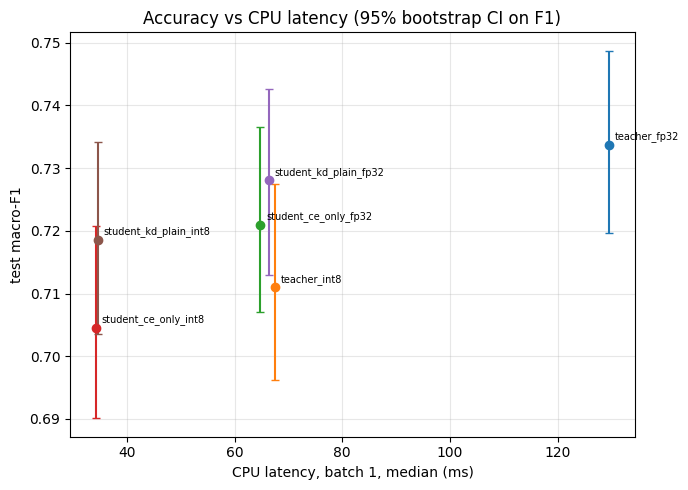

════ PHASE 3b DONE — SEND ALL ════ REPORT BACK ════ BLOCKS ABOVE ════
Saved to: phase3b_outputs


In [11]:
# CELL 8: Baseline B results + combined view + save
rngB = np.random.default_rng(1)
P_B = {k: np.stack([r["test_probs"] for r in rs]).argmax(2) for k, rs in VRES.items()}      # (seeds, N)
def f1_seedmean(pred, s): return np.mean([macro_f1_np(y_te[s], pred[k][s]) for k in range(pred.shape[0])])
keys = list(P_B); ref = ("trim2", "ce_only")
bootB = {k: np.empty(N_BOOT) for k in keys}; bootT = np.empty(N_BOOT)
for b in range(N_BOOT):
    s = rngB.integers(0, len(y_te), len(y_te)); bootT[b] = macro_f1_np(y_te[s], P_T[s])
    for k in keys: bootB[k][b] = f1_seedmean(P_B[k], s)
def cs(x): return f"[{np.percentile(x,2.5):+.4f},{np.percentile(x,97.5):+.4f}]"
t_f1 = macro_f1_np(y_te, P_T); t_mean = float(np.mean([macro_f1_np(y_te, P_T_ALL[k].argmax(1)) for k in range(P_T_ALL.shape[0])]))
print("=" * 70); print("════ REPORT BACK: BASELINE B RESULTS (test macro-F1) ════"); print("=" * 70)
rows = []
for k in keys:
    ps = [macro_f1_np(y_te, P_B[k][i]) for i in range(P_B[k].shape[0])]; m = float(np.mean(ps))
    rows.append({"variant/arm": f"{k[0]}/{k[1]}", "vocab": len(VARIANTS[k[0]]["kept"]), "params_M": VAR_PARAMS[k[0]] / 1e6,
                 "test_UNK_%": 100 * VARIANTS[k[0]]["oov"], "seeds": len(ps), "macro_F1": m, "seed_std": float(np.std(ps, ddof=1)) if len(ps) > 1 else np.nan,
                 "Δ_vs_trim2/ce_only": "-" if k == ref else (f"{m - np.mean([macro_f1_np(y_te, P_B[ref][i]) for i in range(P_B[ref].shape[0])]):+.4f} " + cs(bootB[k] - bootB[ref])) if ref in P_B else "n/a",
                 "Δ_vs_teacher(frozen)": f"{m - t_f1:+.4f} " + cs(bootB[k] - bootT)})
tableB = pd.DataFrame(rows); print(tableB.round(4).to_string(index=False))
print(f"\nTeacher reference: frozen seed {BEST_T_SEED} = {t_f1:.4f} | mean of the 3 Phase 2 teacher seeds = {t_mean:.4f}")
print("Read it as: if full-vocab ce_only is clearly above trim2 (CI excludes 0), trimming is costing accuracy and Phase 4 should use a larger vocab.")

plt.figure(figsize=(7, 5))
for n, r in QRES.items():
    plt.errorbar(r["lat_med"], r["f1"], yerr=[[r["f1"] - np.percentile(boot[n], 2.5)], [np.percentile(boot[n], 97.5) - r["f1"]]], fmt="o", capsize=3)
    plt.annotate(n, (r["lat_med"], r["f1"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
plt.xlabel("CPU latency, batch 1, median (ms)"); plt.ylabel("test macro-F1"); plt.title("Accuracy vs CPU latency (95% bootstrap CI on F1)")
plt.grid(alpha=0.3); plt.tight_layout(); (OUT_DIR / "figures").mkdir(exist_ok=True)
plt.savefig(OUT_DIR / "figures" / "pareto_latency_f1.png", dpi=150, bbox_inches="tight"); plt.show()

tableA.to_csv(OUT_DIR / "baselineA_quantization.csv", index=False); tableB.to_csv(OUT_DIR / "baselineB_vocab.csv", index=False)
(OUT_DIR / "phase3b_summary.json").write_text(json.dumps({
    "teacher_frozen_f1": t_f1, "teacher_3seed_mean_f1": t_mean,
    "A": {n: {k: (float(v) if not isinstance(v, np.ndarray) else None) for k, v in r.items() if k != "pred"} for n, r in QRES.items()},
    "B": {f"{k[0]}/{k[1]}": {"macro_f1": float(np.mean([macro_f1_np(y_te, P_B[k][i]) for i in range(P_B[k].shape[0])])), "params": int(VAR_PARAMS[k[0]]),
                             "test_unk": VARIANTS[k[0]]["oov"], "n_seeds": int(P_B[k].shape[0])} for k in keys}}, indent=2))
print("=" * 70); print("════ PHASE 3b DONE — SEND ALL ════ REPORT BACK ════ BLOCKS ABOVE ════"); print("=" * 70); print("Saved to:", OUT_DIR)